# Analyzing EMRI Simulations with EMRICode

This notebook demonstrates some of the analysis tools available in EMRICode. We'll examine how orbital parameters and conserved quantities evolve throughout an inspiral, compare simulations performed with different numerical tolerances, and explore the frequency content of the resulting gravitational-wave signals.

We'll start by importing the necessary modules and setting up our working directories.

In [1]:
import sys
from pathlib import Path

# Locate the repository root
HERE = Path.cwd()

if (HERE / "MainLoopStreamline.py").is_file():
    ROOT = HERE
elif (HERE.parent / "MainLoopStreamline.py").is_file():
    ROOT = HERE.parent
else:
    raise FileNotFoundError(
        "Could not locate the EMRICode repository. "
        "Launch Jupyter from the repository root or examples/ directory.")

# Make EMRICode modules importable.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Directory containing example simulation data.
EXAMPLE_DATA = ROOT / "examples" / "example_data"

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt

# EMRICode modules
import MainLoopStreamline as ml
import OrbitPlotter as op
import MetricMathStreamline as mm

print(f"EMRICode root: {ROOT}")
print(f"Example data:  {EXAMPLE_DATA}")

EMRICode root: c:\Users\camcinto\OneDrive - NASA\Documents\GitHub\Black-Hole-Stuff
Example data:  c:\Users\camcinto\OneDrive - NASA\Documents\GitHub\Black-Hole-Stuff\examples\example_data


We begin with two inspiral simulations using identical initial conditions but different numerical integration tolerances: `err_target=1e-10` and `err_target=1e-12`.

Comparing these simulations allows us to examine how the integration tolerance affects computational runtime and the resulting orbital evolution. In particular, we'll look at differences in the orbital parameters, geodesic constants of motion, and predicted plunge times.

### Generating the inspirals (optional)

The following cell generates two inspirals with identical initial conditions and different integration tolerances. Generating these simulations can take several minutes, so this step can be skipped if the corresponding data files already exist.

On the author's laptop, the `1e-10` simulation took approximately 7 minutes, while the `1e-12` simulation took approximately 15 minutes. Actual runtimes depend on the system and execution environment.

In [ ]:
p, e, inc, a, mu = 13, 0.6, -np.pi/6, 0.8, 1e-4

orbit1 = ml.EMRIGenerator(a, mu, params=[p, e, inc], err_target=1e-10, label="1e-10 inspiral")
orbit2 = ml.EMRIGenerator(a, mu, params=[p, e, inc], err_target=1e-12, label="1e-12 inspiral")

# Save the data to the directory
ml.save_emri_data(orbit1, filename="loose_error", folder=EXAMPLE_DATA, auto=False)
ml.save_emri_data(orbit2, filename="tighter_error", folder=EXAMPLE_DATA, auto=False)

Normalizing initial state


 87%|████████▋ | 8737623/10000001 [06:43<00:58, 21659.77it/s, Semilat: 7.872, Ecc 0.352, Peri: 5.824, Theta_min: -0.169*pi]            


Normalizing initial state


 87%|████████▋ | 8711692/10000001 [14:37<02:09, 9930.91it/s, Semilat: 7.866, Ecc 0.354, Peri: 5.809, Theta_min: -0.169*pi]            


Overwriting loose_error.h5...
Overwriting tighter_error.h5...


'tighter_error.h5'

### Loading the inspirals

If you've already generated and saved the simulations, run the following cell to load them without repeating the calculations. The loaded data includes the orbital trajectories and reconstructed quantities needed for the subsequent analysis.

In [2]:
# Run this cell to load the already-generated data
orbit1 = ml.load_emri_data(filename="loose_error", folder=EXAMPLE_DATA)
orbit2 = ml.load_emri_data(filename="tighter_error", folder=EXAMPLE_DATA)

Loading C:\Users\camcinto\OneDrive - NASA\Documents\GitHub\Black-Hole-Stuff\examples\example_data\loose_error.h5
Done
Loading C:\Users\camcinto\OneDrive - NASA\Documents\GitHub\Black-Hole-Stuff\examples\example_data\tighter_error.h5
Done


### Examining the orbital trajectories

Now that we have our simulations, we can begin exploring their orbital evolution.

Because these inspirals contain many thousands of orbital cycles, plotting the entire trajectory can produce figures that are too dense to interpret. Instead, we can use `op.plotvalues()` to examine selected time intervals in greater detail.

We'll compare the two simulations at different stages of the inspiral to see how their trajectories evolve and where differences between them become apparent.

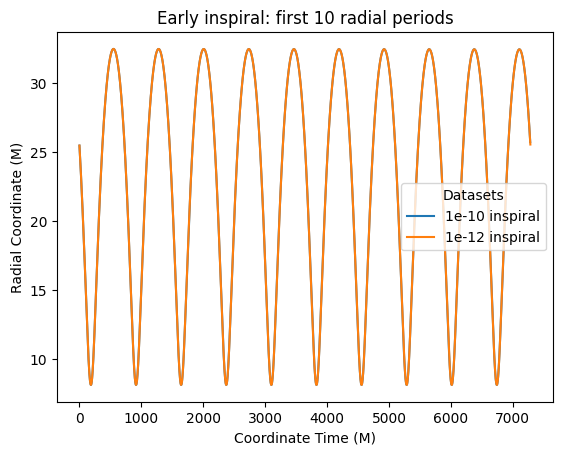

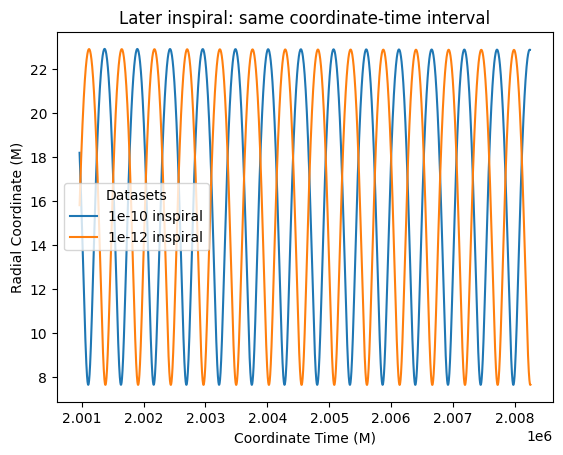

In [3]:
# Use the first 10 radial periods to define a plotting window.
duration = orbit1["tracktime"][10]
fig1, ax1 = op.plotvalues([orbit1, orbit2], yvalue="radius", xvalue="time", end=duration)
ax1.set_title("Early inspiral: first 10 radial periods")

# Examine another window halfway through the radial-orbit count.
midpoint = orbit1["tracktime"][len(orbit1["tracktime"])//2]
fig2, ax2 = op.plotvalues([orbit1, orbit2], yvalue="radius", xvalue="time", start=midpoint, end=midpoint + duration)
ax2.set_title("Later inspiral: same coordinate-time interval")

plt.show()

The plots show that both orbits have become smaller and less eccentric as the inspiral progresses. We can also see that the trajectories have accumulated a noticeable phase difference, despite starting from identical initial conditions. This reflects the sensitivity of the accumulated orbital phase to numerical integration tolerance.

However, differences in orbital phase do not necessarily imply significant differences in the overall inspiral evolution. To investigate this, we can examine the secular evolution of the orbital parameters and geodesic constants of motion, rather than the individual orbital oscillations.

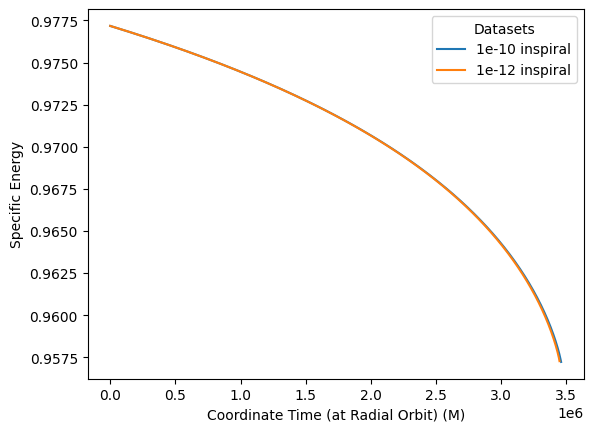

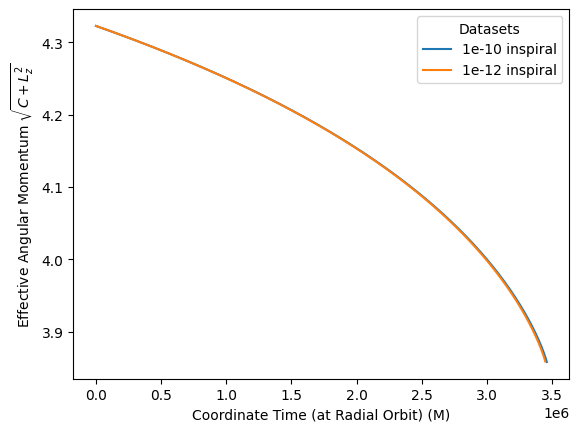

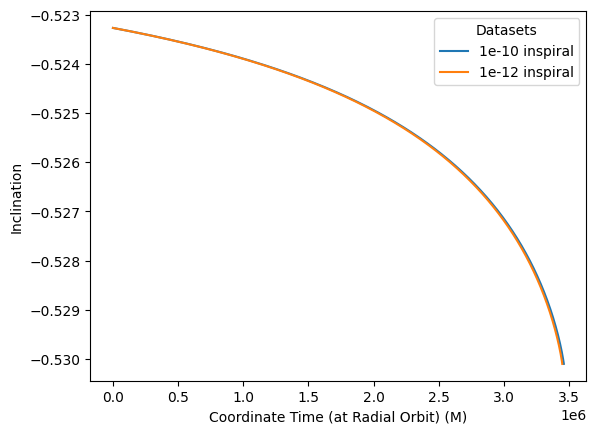

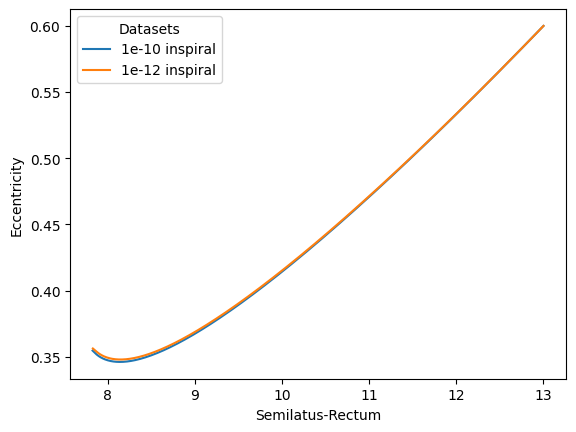

                         |    1e-10 inspiral    |    1e-12 inspiral   
----------------------------------------------------------------------
Time to plunge           |           3.4607e+06 |           3.4484e+06
Radial orbit count       |                 6420 |                 6389
Minimum eccentricity     |             0.346114 |             0.347939
Final eccentricity       |             0.351709 |             0.354171
Final semilatus rectum   |             7.872237 |             7.865706
Final energy             |             0.957249 |             0.957298
Final effective L        |             3.858351 |             3.859010


In [4]:
# Compare the evolution of energy and effective angular momentum.
fig1, ax1 = op.plotvalues([orbit1, orbit2], yvalue="energy", xvalue="tracktime")
fig2, ax2 = op.plotvalues([orbit1, orbit2], yvalue="approx_L", xvalue="tracktime")

# Examine the evolution of the orbital parameters.
fig3, ax3 = op.plotvalues([orbit1, orbit2], yvalue="inc", xvalue="tracktime")
fig4, ax4 = op.plotvalues([orbit1, orbit2], yvalue="ecc", xvalue="semilat")
plt.show()

# Compare selected quantities from the two inspirals.
def summary_values(orbit):
    return {"Time to plunge": orbit["time"][-1] - orbit["time"][0],
            "Radial orbit count": len(orbit["tracktime"]),
            "Minimum eccentricity": np.min(np.real(orbit["e"])),
            "Final eccentricity": np.real(orbit["e"][-2]),
            "Final semilatus rectum": np.real(orbit["p"][-2]),
            "Final energy": orbit["energy"][-2],
            "Final effective L": np.sqrt(orbit["phi_momentum"][-2]**2 + orbit["carter"][-2])}

values1 = summary_values(orbit1)
values2 = summary_values(orbit2)

label_width = 24
col_width = 20

print(
    f'{"":<{label_width}} | '
    f'{orbit1["name"]:^{col_width}} | '
    f'{orbit2["name"]:^{col_width}}'
)
print("-" * (label_width + 2 * col_width + 6))

for label in values1:
    v1, v2 = values1[label], values2[label]

    if label == "Radial orbit count":
        print(f"{label:<{label_width}} | {v1:>{col_width}d} | {v2:>{col_width}d}")
    elif label == "Time to plunge":
        print(f"{label:<{label_width}} | {v1:>{col_width}.4e} | {v2:>{col_width}.4e}")
    else:
        print(f"{label:<{label_width}} | {v1:>{col_width}.6f} | {v2:>{col_width}.6f}")

### Comparing the numerical tolerances

Both inspirals exhibit broadly similar orbital evolution, but differences become apparent as the simulations progress. These differences demonstrate the sensitivity of the results to the numerical integration tolerance. However, comparing only two tolerances is not sufficient to establish which simulation is more accurate or whether either has converged to the correct solution.

To quantify these differences, we can calculate the fractional deviation between corresponding orbital quantities in the two simulations. We'll examine these deviations using two different time coordinates:

- **Coordinate time:** Comparing the simulations at the same physical coordinate time allows us to see how their predicted orbital evolution diverges.
- **Normalized inspiral time:** Rescaling each simulation's time coordinate so that its endpoint corresponds to 1 allows us to compare the overall shapes of their evolution, independently of differences in the total inspiral duration.

Together, these comparisons help distinguish differences in the timing of the inspiral from differences in how the orbital quantities evolve.

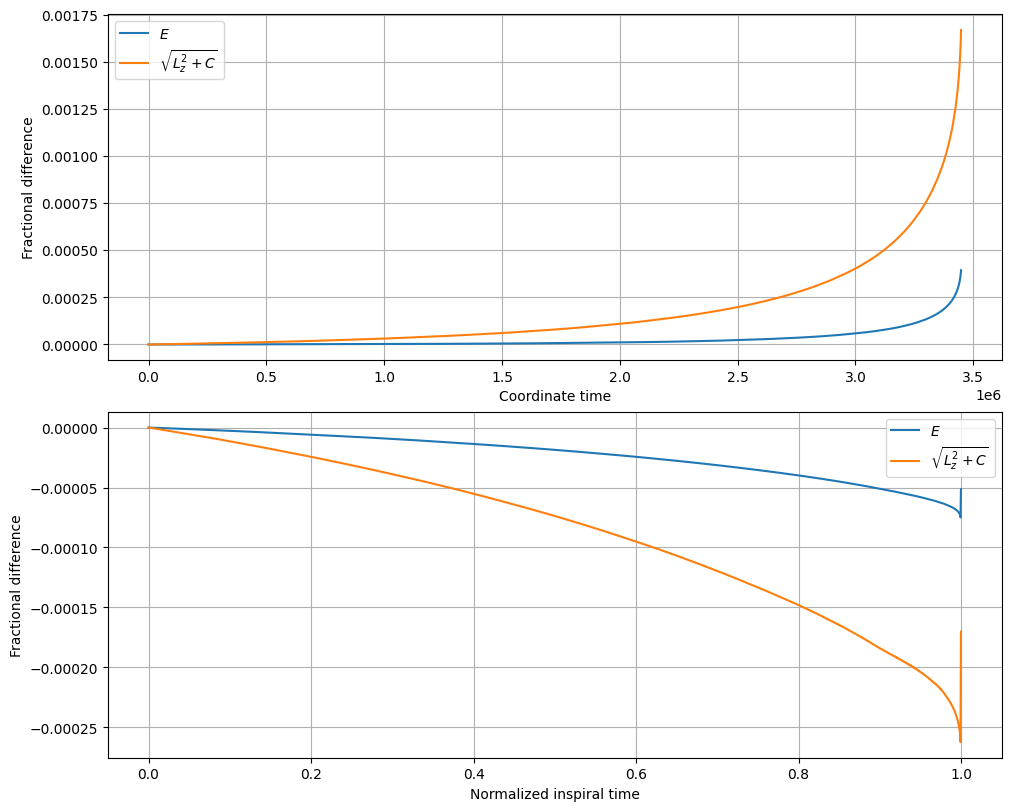

In [5]:
import scipy.interpolate as spi

# Extract the quantities to compare.
def orbital_quantities(orbit):
    return {"Energy": np.asarray(orbit["energy"]),
            "L_eff": np.sqrt(orbit["phi_momentum"]**2 + orbit["carter"])}

# Interpolate a quantity onto a shared time grid.
def interpolate(orbit, values, grid, normalized=False):
    t = np.asarray(orbit["tracktime"])
    if normalized:
        t0 = orbit["time"][0]
        tf = orbit["time"][-1]
        t = (t - t0) / (tf - t0)
    return spi.CubicSpline(t, values, extrapolate=False)(grid)


q1 = orbital_quantities(orbit1)
q2 = orbital_quantities(orbit2)

# Common coordinate-time interval.
t_start = max(orbit1["tracktime"][0], orbit2["tracktime"][0])
t_end = min(orbit1["tracktime"][-1], orbit2["tracktime"][-1])
common_time = np.linspace(t_start, t_end, len(orbit1["tracktime"]))

# Common normalized-time interval.
def normalized_tracktime(orbit):
    t0, tf = orbit["time"][0], orbit["time"][-1]
    return (np.asarray(orbit["tracktime"]) - t0) / (tf - t0)

s1 = normalized_tracktime(orbit1)
s2 = normalized_tracktime(orbit2)

norm_time = np.linspace(max(s1[0], s2[0]), min(s1[-1], s2[-1]), len(orbit1["tracktime"]))

# Plot fractional differences.
fig, axes = plt.subplots(2, figsize=(10, 8), layout="constrained")

quantities = {"Energy": r"$E$",
              "L_eff": r"$\sqrt{L_z^2+C}$"}

for label, latex_label in quantities.items():
    # Compare at equal coordinate time.
    v1 = interpolate(orbit1, q1[label], common_time)
    v2 = interpolate(orbit2, q2[label], common_time)
    axes[0].plot(common_time, (v1 - v2) / v2, label=latex_label)

    # Compare at equal normalized inspiral time.
    v1 = interpolate(orbit1, q1[label], norm_time, normalized=True)
    v2 = interpolate(orbit2, q2[label], norm_time, normalized=True)
    axes[1].plot(norm_time, (v1 - v2) / v2, label=latex_label)

axes[0].set_xlabel("Coordinate time")
axes[1].set_xlabel("Normalized inspiral time")

for ax in axes:
    ax.set_ylabel("Fractional difference")
    ax.grid()
    ax.legend()

plt.show()

In terms of specific energy $E$ and effective angular momentum $L_{eff}$, the first plot shows us once again that the less-strict orbit1 lags in decay in absolute time, but the second plot shows that $E$ and $L_{eff}$ values are much closer and always lower for the same normalized time; the effective shape of the evolution, or in other words the relative rates of radiation reaction, does not seem to be as affected by the tolerance as the timing is.

Now let's look into gravitational wave signals. Signal strength is dependent on distance, so let's come up with a reasonable value. The black hole at center of the Milky Way galaxy, Sagittarius A*, has a mass $M_{BH} = 4.3 \cdot 10^{6} M_{\odot{}}$ and is roughly 27 thousand light years away. In geometric units, that's roughly $4.02 \cdot 10^{10} M_{BH}$. We will assume that Earth lies in Sag A*'s equatorial plane, and that our detector samples the signal once per unit of geometric time (just over 21 seconds) over the course of the inspiral (roughly 27 months for both).

The first plot shows that the less restrictive `1e-10` simulation evolves more slowly in coordinate time, with both the specific energy $E$ and effective angular momentum $L_{\mathrm{eff}}$ decreasing more gradually. However, when we compare the simulations at equal normalized inspiral times, the fractional differences become much smaller. This suggests that the overall shapes of the inspiral evolution are less sensitive to the integration tolerance than the total inspiral duration.

### Gravitational-wave signals

We can now use the simulated trajectories to examine their gravitational-wave signals. To express the waveforms in physical units, we first need to specify a central black hole mass and a distance to the observer.

As an illustrative example, we'll adopt parameters similar to those of Sagittarius A*, the supermassive black hole at the center of the Milky Way. Sagittarius A* has a mass of approximately $M_{BH} = 4.3\times10^6 M_\odot$ and is located roughly 27,000 light-years from Earth. In geometric units, this corresponds to an observer distance of approximately $D \approx 4.02\times10^{10}M_{\mathrm{BH}}$.

For simplicity, we'll place the observer in the black hole's equatorial plane. We'll also sample the gravitational-wave signal at intervals of one geometric time unit, corresponding to approximately 21.2 seconds for our chosen black hole mass.

With this scaling, the simulated inspirals span approximately 27 months of physical time.

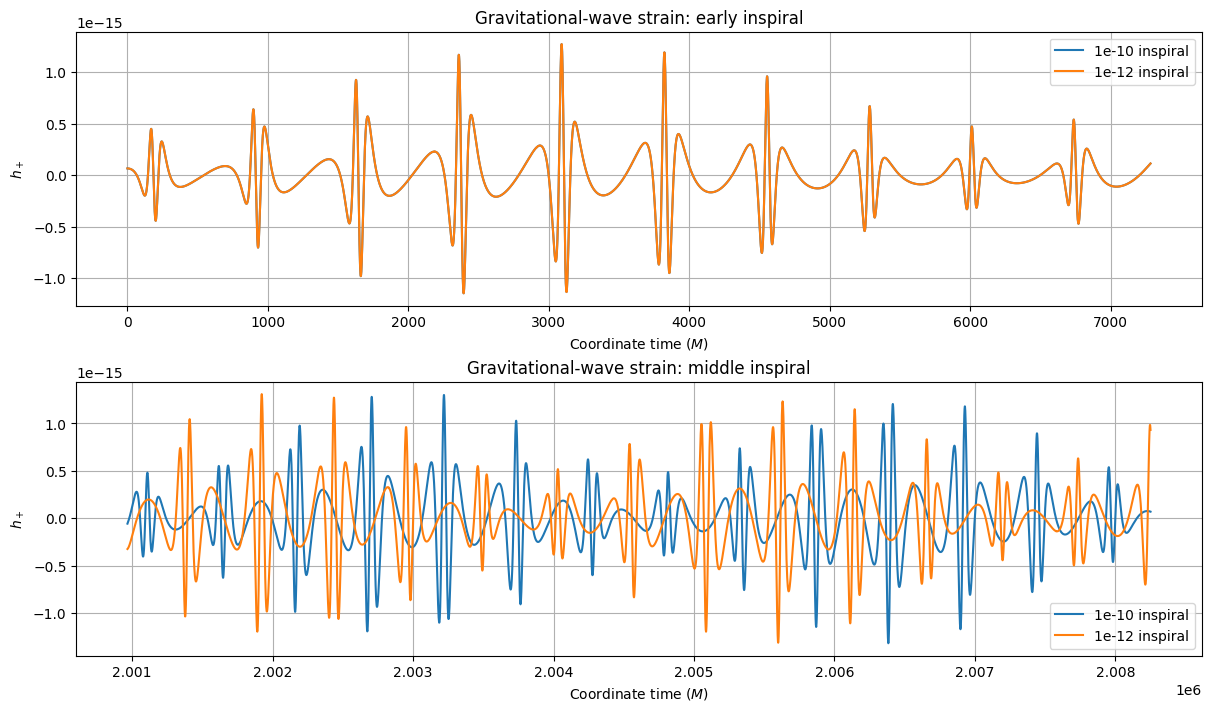

In [6]:
# Observer position and waveform sampling, in geometric units.
distance = 4.02e10
sample_frequency = 1.0
to_observer = [1, 0, 0]  # Equatorial observer; spin axis aligned with z.

fig, axes = plt.subplots(2, figsize=(12, 7), layout="constrained")

# Compare the plus polarization at the beginning and middle of the inspiral.

for orbit in (orbit1, orbit2):
    h_plus1, h_cross1, time1 = mm.full_transform2(orbit, 
                                                  distance=distance,
                                                  samp_freq=sample_frequency,
                                                  n_hat=to_observer,
                                                  end=duration)
    h_plus2, h_cross2, time2 = mm.full_transform2(orbit, 
                                                  distance=distance,
                                                  samp_freq=sample_frequency,
                                                  n_hat=to_observer,
                                                  start=midpoint,
                                                  end=midpoint + duration)
    axes[0].plot(time1, h_plus1, label=orbit["name"])
    axes[1].plot(time2, h_plus2, label=orbit["name"])

for ax in axes:
    ax.set_xlabel(r"Coordinate time ($M$)")
    ax.set_ylabel(r"$h_+$")
    ax.grid()
    ax.legend()

axes[0].set_title("Gravitational-wave strain: early inspiral")
axes[1].set_title("Gravitational-wave strain: middle inspiral")

plt.show()

As with the radial trajectories, the gravitational-wave signals agree closely near the beginning of the inspiral but develop a noticeable phase difference as the evolution progresses.

To investigate how these differences appear in the frequency domain, we can examine the Fourier transforms of the waveforms. This allows us to identify the dominant gravitational-wave frequencies and compare their spectral content without focusing on the accumulated phase differences in the time-domain signals.

c:\Users\camcinto\OneDrive - NASA\Documents\GitHub\Black-Hole-Stuff\OrbitPlotter.py:2185: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[i].legend(title=data["name"])


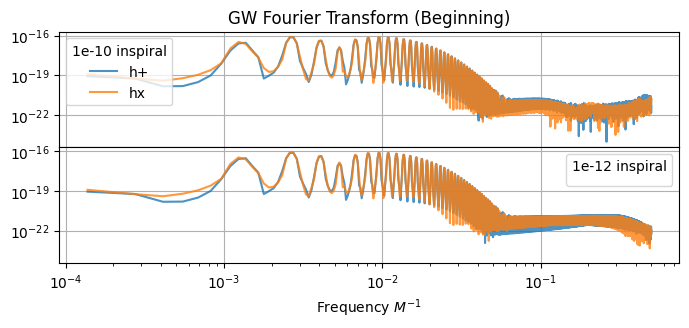

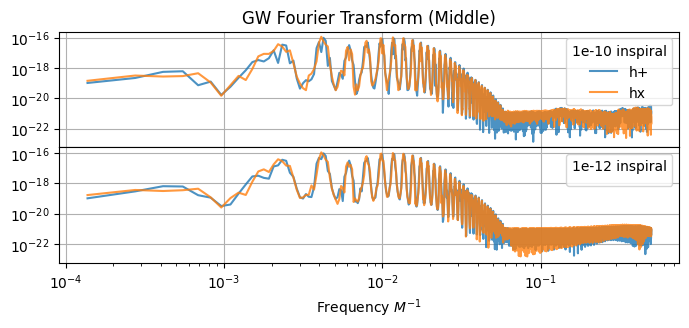

1e-10 inspiral (Beginning)
Power Distribution among 3642 bins
50% of spectral power:      9 bins (0.25%)
90% of spectral power:      29 bins (0.80%)
99% of spectral power:      52 bins (1.43%)
Frequency resolution: 1.37268e-04 M^-1
 Peak |   Frequency (M^-1) |    Power (%)
-------------------------------------------
    1 |       2.745367e-03 |       7.1958
    2 |       9.608785e-03 |       6.7334
    3 |       1.098147e-02 |       6.3086
    4 |       8.236102e-03 |       5.5115
    5 |       1.235415e-02 |       5.0359

1e-12 inspiral (Beginning)
Power Distribution among 3642 bins
50% of spectral power:      9 bins (0.25%)
90% of spectral power:      29 bins (0.80%)
99% of spectral power:      52 bins (1.43%)
Frequency resolution: 1.37268e-04 M^-1
 Peak |   Frequency (M^-1) |    Power (%)
-------------------------------------------
    1 |       2.745367e-03 |       7.1958
    2 |       9.608785e-03 |       6.7336
    3 |       1.098147e-02 |       6.3088
    4 |       8.236102e-03 

In [7]:
# Compare GW spectra near the beginning of the inspiral.
fig1, ax1, report1 = op.justfouriernew([orbit1, orbit2],
                                       distance=4.02e10,
                                       samp_freq=1.0,
                                       n_hat=to_observer,
                                       end=duration,
                                       analyze_peaks=5)  # analyze_peaks=5 gives us information about the 5 most prominent peaks
ax1[0].set_xscale("log")
ax1[0].set_title("GW Fourier Transform (Beginning)")

# Repeat for the middle of the inspiral.
fig2, ax2, report2 = op.justfouriernew([orbit1, orbit2],
                                       distance=4.02e10,
                                       samp_freq=1.0,
                                       n_hat=to_observer,
                                       start=midpoint,
                                       end=midpoint + duration,
                                       analyze_peaks=5)
ax2[0].set_xscale("log")
ax2[0].set_title("GW Fourier Transform (Middle)")

plt.show()

# Display the peak-analysis summaries.
for label, reports in [("Beginning", report1), ("Middle", report2)]:
    for orbit, report in zip([orbit1, orbit2], reports):
        print(op.print_peak_summary(f'{orbit["name"]} ({label})', report))



### Comparing the Fourier spectra

Near the beginning of the inspiral, the two simulations produce nearly identical frequency spectra. Their five strongest peaks occur at the same frequencies and have almost identical relative powers. In both cases, fewer than 1% of the frequency bins contain 90% of the total spectral power, indicating that the signal is concentrated around a relatively small number of prominent frequencies.

By the middle of the inspiral, the dominant peaks have shifted toward higher frequencies, consistent with the increasing orbital frequencies as the secondary approaches the central black hole. Despite the phase differences in their time-domain waveforms, we can see that both simulations still place their five strongest peaks in the same bins; however, their relative peak powers now differ noticeably. These results suggest that the integration tolerance has a greater effect on the distribution of spectral power than on the locations of the dominant frequency peaks over these intervals. Note that the finite frequency resolution means that smaller frequency differences may not be resolved by this analysis.

### Gravitational-wave spectrogram

So far, we've examined the gravitational-wave frequency spectra at two different stages of the inspiral and seen that the spectra evolve over time. To visualize this evolution, we can construct a spectrogram of the entire inspiral. A spectrogram divides the signal into shorter, overlapping time windows and calculates the frequency content within each window, allowing us to track how the dominant gravitational-wave frequencies change over time.


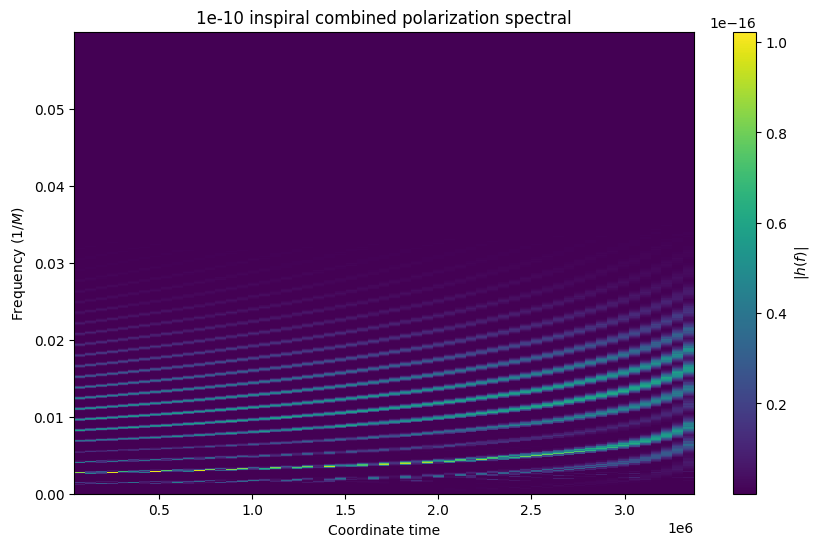

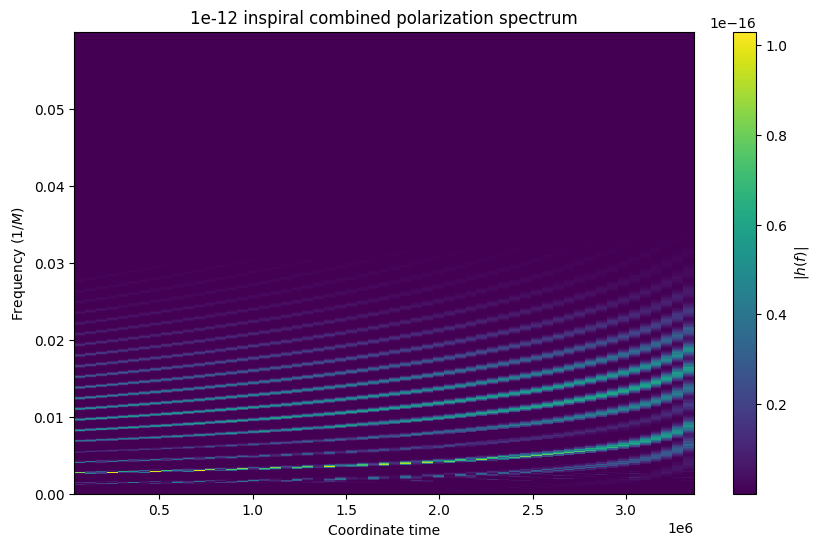

In [8]:
# Plot the combined GW polarization amplitude spectrograms.
# Each spectrogram shows sqrt(|h+|² + |hx|²) in the time-frequency domain.

fig1, ax1, center_times1, freqs1, spec1 = op.plot_spectrogram(orbit1, 
                                                              distance=4.02e10, 
                                                              n_hat=to_observer, 
                                                              max_freq=0.06)
ax1.set_title(orbit1["name"] + " combined polarization spectral")

fig2, ax2, center_times2, freqs2, spec2 = op.plot_spectrogram(orbit2, 
                                                              distance=4.02e10, 
                                                              n_hat=to_observer, 
                                                              max_freq=0.06)
ax2.set_title(orbit2["name"] + " combined polarization spectrum")
plt.show()


### Summary

In this notebook, we've explored several of EMRICode's analysis tools, from examining orbital trajectories and the evolution of orbital parameters to generating and analyzing gravitational-wave signals.

Comparing simulations with different numerical integration tolerances revealed that relatively small differences in orbital evolution can accumulate into noticeable differences in orbital and gravitational-wave phase. At the same time, the simulations retained broadly similar secular evolution and dominant gravitational-wave frequency content.

Finally, the full-inspiral spectrograms illustrate how the gravitational-wave frequency structure evolves as the secondary approaches the central black hole.

These examples demonstrate how EMRICode can be used to investigate both the orbital dynamics of EMRIs and their associated gravitational-wave signals. The tools shown here can also be applied to simulations with different initial conditions, black hole spins, mass ratios, and numerical settings.